In [1]:
import dispatch
import dispatch.select as ds; import dispatch.graphics as dg;
import dispatch.yt as dyt
import yt as yt
import matplotlib.pyplot as pl
import numpy as np

In [2]:
data='../data'
run = ''
iout=6
ds = dyt.open_amr(iout=iout,run=run,data=data,verbose=1,copy=True)

      yt patches: 144
domain_dimesions: [12, 12, 1]


yt : [INFO     ] 2020-05-14 10:01:22,405 Parameters: current_time              = 0.6
yt : [INFO     ] 2020-05-14 10:01:22,408 Parameters: domain_dimensions         = [12 12  1]
yt : [INFO     ] 2020-05-14 10:01:22,412 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2020-05-14 10:01:22,414 Parameters: domain_right_edge         = [1.     1.     0.0078]
yt : [INFO     ] 2020-05-14 10:01:22,416 Parameters: cosmological_simulation   = 0.0


/mn/stornext/u3/andriusp/anaconda3/lib/python3.7/site-packages/yt/units/yt_array.py:978: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  ret = super(YTArray, self).__getitem__(item)
/mn/stornext/u3/andriusp/anaconda3/lib/python3.7/site-packages/yt/fields/fluid_fields.py:201: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  new_field[slice_3d] = f
yt : [INFO     ] 2020-05-14 10:01:23,155 xlim = 0.000000 1.000000
yt : [INFO     ] 2020-05-14 10:01:23,157 ylim = 0.000000 1.000000
yt : [INFO     ] 2020-05-14 10:01:23,161 xlim = 0.000000 1.000000
yt


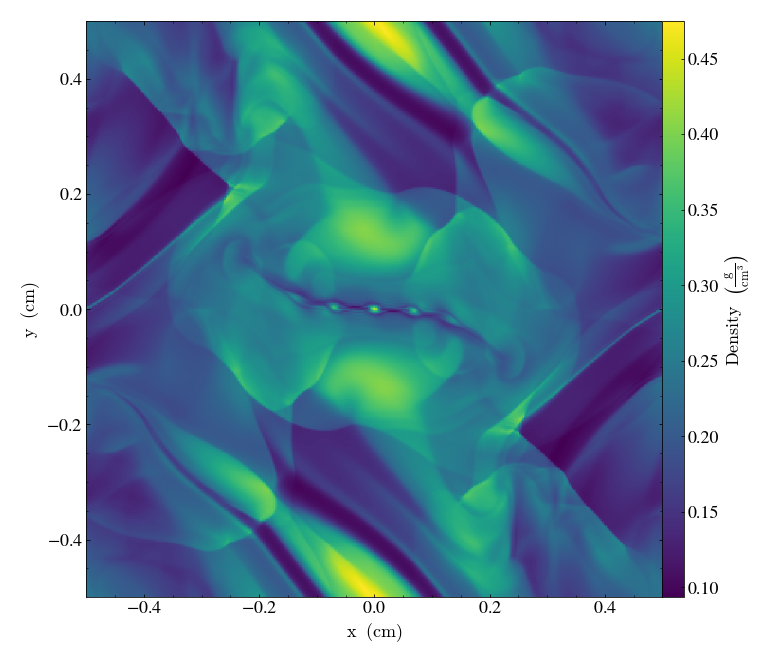
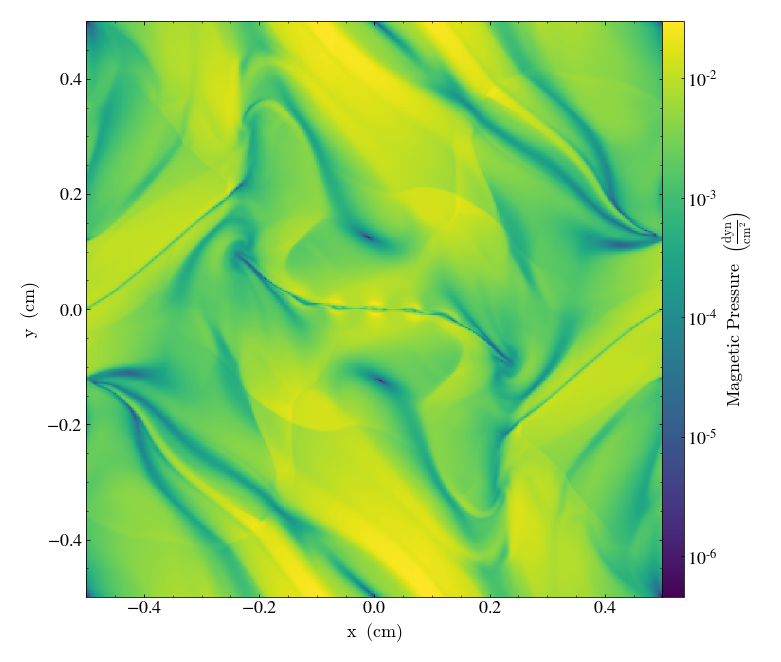

In [3]:
center = [0.5,0.5,0.002]
varfield = 'density'
slc=yt.SlicePlot(ds=ds,axis="z",fields=[varfield,'magnetic_pressure'],center=center,width = ((1,'cm'),(1.0,'cm')))
#slc.set_buff_size(4096)
slc.set_cmap(varfield,"viridis")
slc.set_cmap('magnetic_pressure',"viridis")
#slc.set_cmap(varfield,"gist_gray")
slc.set_log(varfield,False)
#slc.set_zlim("dtime", 1e-2, 1e-4)
#slc.annotate_streamlines('magnetic_field_x', 'magnetic_field_y',field_color='b_mag',density=5.3)#plot_args={'color':'grey'})
#slc.annotate_quiver('magnetic_field_x', 'magnetic_field_y', factor=24, normalize=False)
#slc.annotate_contour('b_mag', take_log=True)
#slc.annotate_grids()
#slc.annotate_timestamp()
slc.show()

# Reference


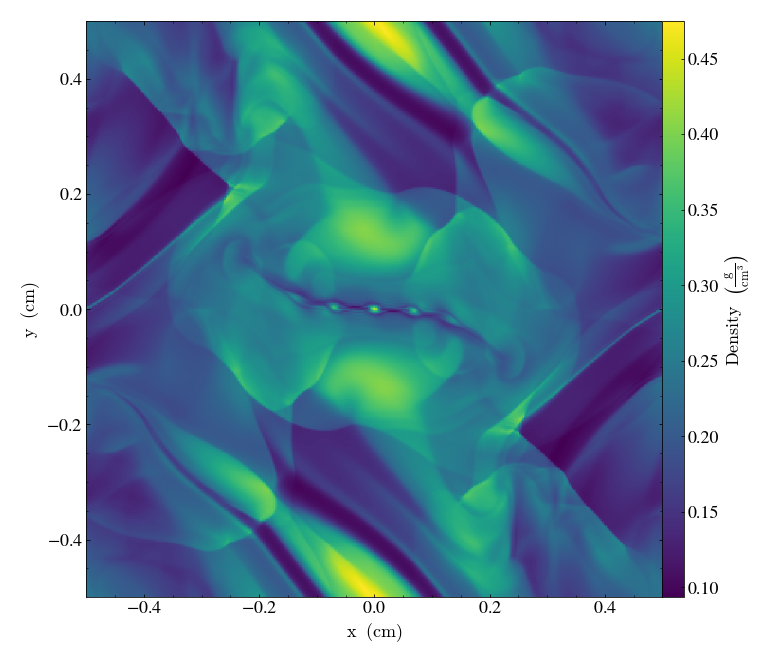
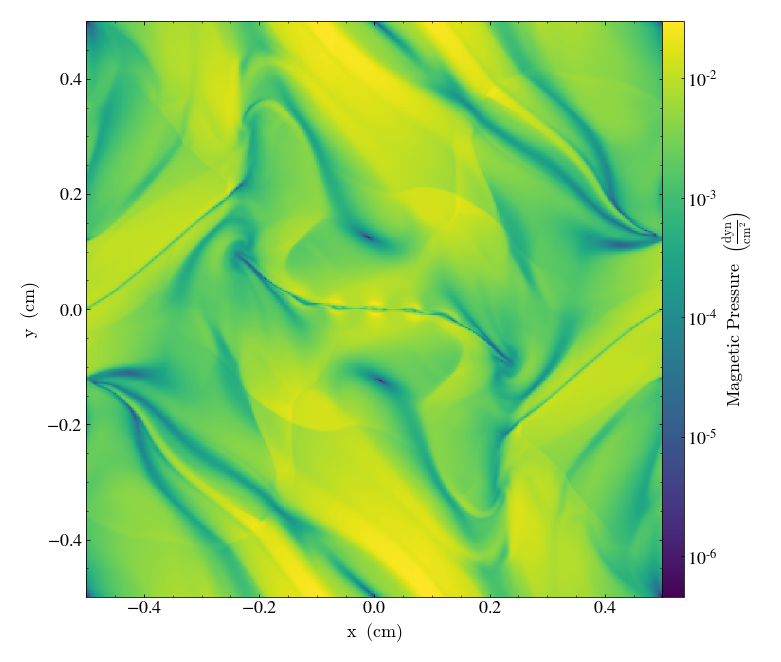

In [4]:
slc.show()

# Scratches

In [ ]:
def im3(pp,iv,vmin,vmax,varname): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    g=pp.patches[0].ng
    m=int(n.max()/2 -1)
    dim = pp.cartesian.dims
    pos_arr = np.zeros([int(dim[0]),int(dim[1]),int(dim[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        pos = (p.position-pp.cartesian.origin)*pp.cartesian.dims
        position = [int(pos[0]), int(pos[1]), int(pos[2])]
        pos_arr[position[0], position[1], position[2]] = p.id
        if (iv==10):
            data= (p.var(5)**2+p.var(6)**2+p.var(7)**2)/(8*np.pi)
            varname='magnetic pressure'
        elif (iv==11):
            data= (p.var(4)*(s.gamma-1.0))
            varname='gas pressure'
        else:
            data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        no_gz=data
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz
      #print(pos_arr)
      #print(np.shape(patch_arr.transpose()))
      #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    if (n[2]==1):
        final = patch_arr[:,:,0].transpose()
    elif (n[0]==1):
        final = patch_arr[0,:,:].transpose()
    elif (n[1]==1):
        final = patch_arr[:,0,:].transpose()
    pl.imshow(final, cmap='viridis')
    pl.title(varname); 
    pl.colorbar(shrink=0.6)

In [ ]:
iout=100
s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
pl.figure(1, figsize=(20,20))
pl.clf()
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
pl.subplot(2,2,1); im3(s, 'd', 470, 530 ,'d')#,ylim0,ylim1)
pl.subplot(2,2,2); im3(s, 'e', -.20, +.20 ,'e' )
        #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
pl.subplot(2,2,3); im3(s, 'ux', -.20, +.20, 'ux')#,ylim0,ylim1)
pl.subplot(2,2,4); im3(s, 'bx', -.20, +.20, 'bx')#,ylim0,ylim1)
pl.tight_layout()
pl.draw()
pl.pause(0.001)
pl.show()

In [ ]:
slc.zoom(3.)